# Lab ANN : Classification des images de vêtements
## But:

Être capable de concevoir et réaliser une IA permettant la classification des images de vêtements.

**Keywords : Fashion-MNIST dataset, PyTorch, ANN**

<center>Copyright : Dr Mohammed BOUSMAH EMSI-2026 — bousmah@gmail.com</center>

**Références :** [Tutoriel PyTorch Fashion-MNIST](https://pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html) ; [documentation torchvision.datasets.FashionMNIST](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html).

uv add torch torchvision numpy matplotlib



In [2]:
# PyTorch (sans TensorFlow ni Keras)
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
# MPS pour les Mac Apple Silicon, CUDA pour les GPU NVIDIA, sinon CPU
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)


PyTorch version: 2.14.1
Device: mps


# Step 1: Dataset(Download dataset)

In [3]:
# Téléchargement de Fashion-MNIST (60 000 images d'entraînement, 10 000 de test)
train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True)
test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True)

# Tableaux NumPy pour conserver les manipulations et figures du TP initial
train_images = train_dataset.data.numpy()
train_labels = train_dataset.targets.numpy()
test_images = test_dataset.data.numpy()
test_labels = test_dataset.targets.numpy()

class_names = ['T-shirt/haut', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Baskets', 'Sac', 'Bottines']


100.0%
100.0%
100.0%
100.0%


## Dataset Manipulation

In [4]:
print(train_images.shape)
print(len(train_labels))
print(train_labels)
print(test_images.shape)
print(len(test_labels))

(60000, 28, 28)
60000
[9 0 0 ... 3 0 5]
(10000, 28, 28)
10000


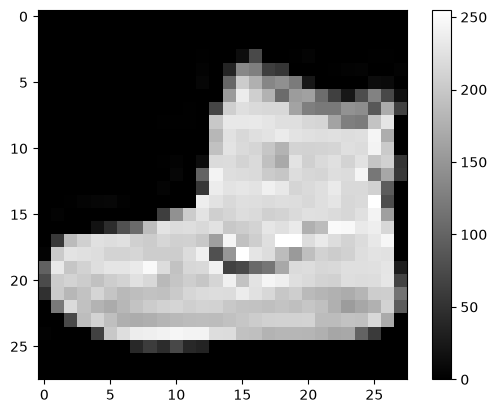

In [5]:
plt.figure()
plt.imshow(train_images[0], cmap="gray")
plt.colorbar()
plt.grid(False)
plt.show()

In [6]:
class_names[train_labels[0]]

'Bottines'

In [7]:
train_images[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   0,  13,  73,   0,   0,   1,   4,   0,   0,   0,   0,   1,
          1,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
          0,  36, 136, 127,  62,  54,   0,   0,   0,   1,   3,   4,   0,
          0,   3],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,
          0, 102, 204, 176, 134, 144, 123,  23,   0,   0,   0,   0,  12,
         10,   0],
       [  

In [8]:
train_labels[0]

np.int64(9)

In [9]:
# Normalisation des pixels dans [0, 1], comme dans le TP original
train_images = train_images.astype(np.float32) / 255.0
test_images = test_images.astype(np.float32) / 255.0


# Step 2: Model (Build & Compile the model)

In [10]:
# Architecture équivalente au modèle Keras initial : Flatten -> Dense(128, ReLU) -> Dense(10)
# nn.Linear produit des logits (sans Softmax), adaptés à CrossEntropyLoss.
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# Équivalents PyTorch de compile(optimizer='adam', loss=SparseCategoricalCrossentropy(from_logits=True))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

# Les DataLoader fournissent les images au format (N, 1, 28, 28)
train_tensor = torch.from_numpy(train_images).unsqueeze(1)
test_tensor = torch.from_numpy(test_images).unsqueeze(1)
train_loader = DataLoader(
    torch.utils.data.TensorDataset(train_tensor, torch.from_numpy(train_labels)),
    batch_size=64, shuffle=True
)
test_loader = DataLoader(
    torch.utils.data.TensorDataset(test_tensor, torch.from_numpy(test_labels)),
    batch_size=256, shuffle=False
)


In [11]:
# Équivalent simple de model.summary()
print(model)
print("Nombre de paramètres entraînables :",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Nombre de paramètres entraînables : 101770


# Step 3: Train

In [12]:
# Équivalent de model.fit(..., epochs=2) : boucle explicite PyTorch
num_epochs = 2
for epoch in range(num_epochs):
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += batch_size
    print(f"Epoch {epoch + 1}/{num_epochs} - loss: {total_loss / seen:.4f} - accuracy: {correct / seen:.4f}")


Epoch 1/2 - loss: 0.5423 - accuracy: 0.8135
Epoch 2/2 - loss: 0.3951 - accuracy: 0.8593


# Step 4: Test

In [13]:
# Équivalent de model.evaluate() et model.predict() + Softmax
model.eval()
test_loss_sum, test_correct, test_seen = 0.0, 0, 0
prediction_batches = []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        test_loss_sum += loss.item() * labels.size(0)
        test_correct += (logits.argmax(dim=1) == labels).sum().item()
        test_seen += labels.size(0)
        probabilities = torch.softmax(logits, dim=1)
        prediction_batches.append(probabilities.cpu().numpy())

test_loss = test_loss_sum / test_seen
test_acc = test_correct / test_seen
predictions = np.concatenate(prediction_batches, axis=0)
print(f"Test loss: {test_loss:.4f}")
print("\nTest accuracy:", test_acc)


Test loss: 0.3987

Test accuracy: 0.858


In [14]:
predictions[0]

array([1.7668109e-04, 2.8809160e-07, 5.3657110e-05, 8.3868828e-05,
       3.5076948e-05, 6.4425699e-02, 2.1916677e-04, 1.2302636e-01,
       5.1943208e-03, 8.0678487e-01], dtype=float32)

In [15]:
np.argmax(predictions[0])

np.int64(9)

In [16]:
def plot_image(i, predictions_array, true_label, img):
  true_label, img = true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])

  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'blue'
  else:
    color = 'red'

  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  true_label = true_label[i]
  plt.grid(False)
  plt.xticks(range(10))
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1])
  predicted_label = np.argmax(predictions_array)

  thisplot[predicted_label].set_color('red')
  thisplot[true_label].set_color('blue')

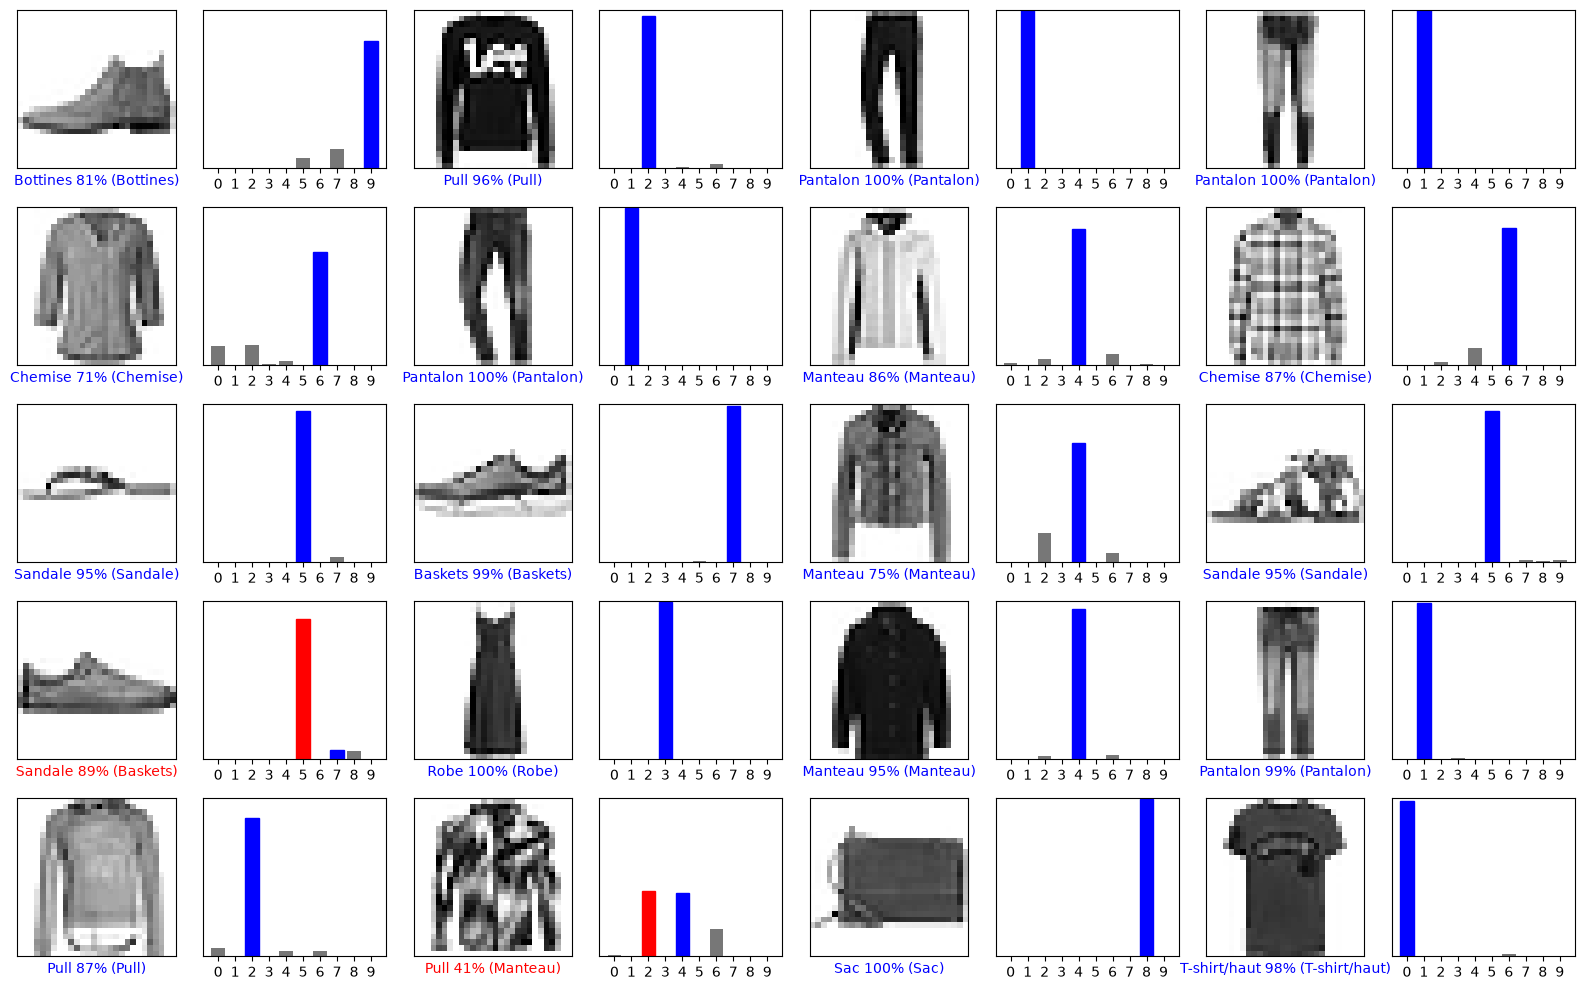

In [17]:
num_rows = 5
num_cols = 4
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i, predictions[i], test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

# Save & Deploy the Model:

In [18]:
# Sauvegarde PyTorch recommandée : poids + métadonnées pour reconstruire le modèle
# Rechargement : checkpoint = torch.load("pytorch_model_fashion_mnist.pth", map_location="cpu", weights_only=True)
# Puis recréer l'architecture nn.Sequential identique et appeler model.load_state_dict(checkpoint["model_state_dict"])
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "architecture": "Flatten-Linear(784,128)-ReLU-Linear(128,10)",
}, "pytorch_model_fashion_mnist.pth")
print("Modèle enregistré : pytorch_model_fashion_mnist.pth")


Modèle enregistré : pytorch_model_fashion_mnist.pth
